# Clase 13 — El modelo de lenguaje como política: token, temperatura, GRPO

**RL a ciegas** · curso de aprendizaje por refuerzo (*reinforcement learning*, RL) · vía profunda

Basado en Ouyang et al. (2022) para RLHF, Shao et al. (2024, DeepSeekMath) para GRPO, DeepSeek-AI (2025, DeepSeek-R1) para las recompensas verificables y Stanford CS224R (2026), clase 10. El modelo es `Qwen/Qwen2.5-0.5B-Instruct` (Qwen Team, 2024).

**La pregunta de hoy:** si cada palabra que escribe un asistente es una acción, ¿qué es la recompensa y quién la pone?

En la clase 9 una red recurrente predecía el próximo carácter; en la clase 11 una política elegía flechas en la cueva y la reforzábamos con policy gradient; en la clase 12 la recompensa la aprendía un modelo a partir de preferencias. Hoy juntamos las tres cosas con un modelo de lenguaje real:

1. **Probabilidades del próximo token**: el modelo es una política π(token | texto).
2. **La respuesta como episodio**: estado, acción, episodio y una recompensa que llega al final.
3. **Temperatura y muestreo**: la perilla que va de explotar a explorar.
4. **Un verificador para cuentas**: una recompensa que no hay que aprender.
5. **Ventajas de GRPO en un grupo**: muestrear varias respuestas, puntuarlas y compararlas entre sí.
6. **El grupo como línea de base**: por qué GRPO no necesita un crítico.

> **Tiempo y recursos.** El modelo tiene 500 millones de parámetros, es abierto (no pide cuenta ni token) y se descarga una vez (≈ 1 GB). En CPU el notebook tarda varios minutos (entre 5 y 15, según la máquina); con GPU, uno o dos. **No vamos a entrenar el modelo**: muestreamos, puntuamos y calculamos lo que GRPO necesita para dar un paso. Un modelo tan chico se equivoca seguido, y esos errores son parte de la lección.

## Preparación

La primera celda escribe el archivo `cave_env.py` con **la cueva** de todo el curso; la usamos en la sección 2 para comparar una partida con una respuesta. No hace falta leerla.

In [1]:
%%writefile cave_env.py
"""
cave_env.py — La cueva a ciegas (entorno del mini curso de RL).

Una grilla discreta. El agente no ve el mapa: solo se entera de que hay una
pared cuando choca contra ella (en el juego, la pared se pinta de gris claro).
La salida es el cuadrado verde 'G'.

API mínima (estilo Gymnasium, sin dependencias):
    env = CaveEnv()
    s = env.reset()                 # estado = índice entero de la casilla
    s, r, done, info = env.step(a)  # a en {0:arriba, 1:derecha, 2:abajo, 3:izquierda}
    info["bump"]                    # True si chocó con una pared

Para la clase 4 (planificar con mapa): env.P[s, a, s'] y env.R[s, a].
"""
import numpy as np

CAVE_MAP = [
    "##############",
    "#S...#.......#",
    "#.##.#.####..#",
    "#.#..#....#..#",
    "#.#.####..#.##",
    "#.#......##..#",
    "#.####.#..#..#",
    "#......#.##..#",
    "###.####....G#",
    "##############",
]

ACTIONS = {0: (-1, 0), 1: (0, 1), 2: (1, 0), 3: (0, -1)}
ACTION_NAMES = ["↑", "→", "↓", "←"]


class CaveEnv:
    def __init__(self, cave_map=CAVE_MAP, goal_reward=1.0, step_reward=0.0,
                 bump_reward=0.0, slip=0.0, max_steps=200, seed=None):
        self.grid = np.array([list(row) for row in cave_map])
        self.H, self.W = self.grid.shape
        self.goal_reward, self.step_reward, self.bump_reward = goal_reward, step_reward, bump_reward
        self.slip, self.max_steps = slip, max_steps
        self.rng = np.random.default_rng(seed)
        self.free = [(r, c) for r in range(self.H) for c in range(self.W) if self.grid[r, c] != "#"]
        self.pos2s = {p: i for i, p in enumerate(self.free)}
        self.nS, self.nA = len(self.free), 4
        self.start = self.pos2s[tuple(np.argwhere(self.grid == "S")[0])]
        self.goal = self.pos2s[tuple(np.argwhere(self.grid == "G")[0])]
        self._build_model()
        self.reset()

    # ---------- dinámica ----------
    def _move(self, s, a):
        r, c = self.free[s]
        dr, dc = ACTIONS[a]
        nr, nc = r + dr, c + dc
        if self.grid[nr, nc] == "#":
            return s, True
        return self.pos2s[(nr, nc)], False

    def _reward(self, s_next, bump):
        if s_next == self.goal:
            return self.goal_reward
        return self.step_reward + (self.bump_reward if bump else 0.0)

    def _build_model(self):
        """Modelo del mundo: P[s,a,s'] y R[s,a] (recompensa esperada). La meta es absorbente."""
        nS, nA = self.nS, self.nA
        self.P = np.zeros((nS, nA, nS))
        self.R = np.zeros((nS, nA))
        for s in range(nS):
            for a in range(nA):
                if s == self.goal:
                    self.P[s, a, s] = 1.0
                    continue
                # con prob 1-slip va adonde quiere; con slip, a una dirección perpendicular
                outcomes = [(a, 1 - self.slip)]
                if self.slip > 0:
                    outcomes += [((a + 1) % 4, self.slip / 2), ((a + 3) % 4, self.slip / 2)]
                for aa, p in outcomes:
                    s2, bump = self._move(s, aa)
                    self.P[s, a, s2] += p
                    self.R[s, a] += p * self._reward(s2, bump)

    def reset(self):
        self.s, self.t = self.start, 0
        self.touched = set()          # paredes descubiertas (para dibujar)
        return self.s

    def step(self, a):
        if self.slip > 0 and self.rng.random() < self.slip:
            a = (a + self.rng.choice([1, 3])) % 4
        s2, bump = self._move(self.s, a)
        if bump:
            r, c = self.free[self.s]
            dr, dc = ACTIONS[a]
            self.touched.add((r + dr, c + dc))
        rew = self._reward(s2, bump)
        self.s, self.t = s2, self.t + 1
        done = s2 == self.goal or self.t >= self.max_steps
        return s2, rew, done, {"bump": bump, "reached_goal": s2 == self.goal}

    # ---------- observaciones para Deep RL ----------
    def observe(self, s=None, kind="onehot"):
        s = self.s if s is None else s
        if kind == "onehot":
            x = np.zeros(self.nS, dtype=np.float32); x[s] = 1; return x
        r, c = self.free[s]
        if kind == "coords":
            return np.array([r / (self.H - 1), c / (self.W - 1)], dtype=np.float32)
        if kind == "coords+touch":   # posición + 4 "bigotes" que sienten paredes vecinas
            walls = [float(self.grid[r + dr, c + dc] == "#") for dr, dc in ACTIONS.values()]
            return np.array([r / (self.H - 1), c / (self.W - 1)] + walls, dtype=np.float32)
        raise ValueError(kind)

    # ---------- dibujo ----------
    def to_grid(self, values):
        g = np.full((self.H, self.W), np.nan)
        for s, (r, c) in enumerate(self.free):
            g[r, c] = values[s]
        return g

    def plot(self, values=None, policy=None, ax=None, title=None, cmap="magma",
             show_walls=True, path=None):
        import matplotlib.pyplot as plt
        if ax is None:
            _, ax = plt.subplots(figsize=(self.W * 0.5, self.H * 0.5))
        bg = np.zeros((self.H, self.W, 3))
        if show_walls:
            bg[self.grid == "#"] = 0.8      # gris claro: la pared "tocada"
        ax.imshow(bg)
        if values is not None:
            im = ax.imshow(self.to_grid(values), cmap=cmap, alpha=0.9)
            plt.colorbar(im, ax=ax, fraction=0.03)
        gr, gc = self.free[self.goal]
        ax.add_patch(plt.Rectangle((gc - .5, gr - .5), 1, 1, color="#2ecc71"))
        sr, sc = self.free[self.start]
        ax.text(sc, sr, "S", ha="center", va="center", color="w", fontsize=11, weight="bold")
        if policy is not None:
            for s, (r, c) in enumerate(self.free):
                if s != self.goal:
                    ax.text(c, r, ACTION_NAMES[int(policy[s])], ha="center", va="center",
                            color="cyan", fontsize=11)
        if path is not None:
            rc = np.array([self.free[s] for s in path])
            ax.plot(rc[:, 1], rc[:, 0], "-", color="#3498db", lw=2, alpha=.8)
        ax.set_xticks([]); ax.set_yticks([])
        if title: ax.set_title(title)
        return ax

Overwriting cave_env.py


¿Hay GPU? En Colab: **Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU T4**. Sin GPU corre igual, más lento. La celda instala `transformers` si falta (en Colab ya viene).

In [2]:
import importlib, subprocess, sys
for paquete in ["transformers", "accelerate"]:          # en Colab ya vienen; por las dudas
    if importlib.util.find_spec(paquete) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", paquete], check=True)

import torch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("GPU:", torch.cuda.get_device_name(0)) if DEVICE == "cuda" else print("Sin GPU: corre en CPU (más lento).")

Sin GPU: corre en CPU (más lento).


In [3]:
import os, re, time, warnings
import numpy as np
import matplotlib.pyplot as plt
from cave_env import CaveEnv, ACTION_NAMES

MODELO = "Qwen/Qwen2.5-0.5B-Instruct"
SEMILLA = 0
np.random.seed(SEMILLA); torch.manual_seed(SEMILLA)
T0 = time.time()

**Herramientas** (celda plegada): cargar el modelo, leer sus probabilidades, muestrear, el verificador, las ventajas de GRPO y los dibujos. No hace falta leerla, solo ejecutarla.

In [4]:
# @title Herramientas (no hace falta leer esto)
# Herramientas: no hace falta leer esto
warnings.filterwarnings("ignore")
from collections import Counter, deque
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from transformers import AutoTokenizer, AutoModelForCausalLM
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error(); hf_logging.disable_progress_bar()
warnings.filterwarnings("ignore")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
VERDE, ROJO, GRIS = "#1baf7a", "#e34948", "#9a9a9a"
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "#888888", "axes.titlesize": 12, "font.size": 10.5, "lines.linewidth": 2,
})


def corto(txt, n=90):
    txt = " ".join(str(txt).split())
    return txt if len(txt) <= n else txt[: n - 1] + "…"


# ================= modelo =================
def cargar_modelo(nombre):
    t = time.time()
    dtype = torch.float16 if DEVICE == "cuda" else torch.float32
    tok = AutoTokenizer.from_pretrained(nombre)
    mod = AutoModelForCausalLM.from_pretrained(nombre, dtype=dtype).to(DEVICE).eval()
    print(f"{nombre}: {sum(p.numel() for p in mod.parameters()) / 1e6:.0f} millones de parámetros, "
          f"vocabulario de {len(tok)} tokens (cargado en {time.time() - t:.0f} s)")
    return tok, mod


def texto_chat(mensajes, prefijo=""):
    """El estado completo que ve el modelo: la conversación con la plantilla de chat + lo que ya escribió."""
    return tok.apply_chat_template(mensajes, tokenize=False, add_generation_prompt=True) + prefijo


def usuario(txt, sistema=None):
    return ([{"role": "system", "content": sistema}] if sistema else []) + [{"role": "user", "content": txt}]


def n_tokens(texto):
    return len(tok(texto, add_special_tokens=False).input_ids)


@torch.no_grad()
def logits_proximo(texto):
    ids = tok(texto, return_tensors="pt").to(DEVICE)
    return modelo(**ids).logits[0, -1].float().cpu()


def mostrar_token(t):
    return t.replace(" ", "·").replace("\n", "⏎")


def etiqueta(t):
    """Para los ejes: los tokens de alfabetos que la fuente no dibuja (chino, coreano, …) se nombran."""
    return mostrar_token(t) if all(ord(ch) < 0x2E80 for ch in t) else "(otro alfabeto)"


def es_fin(j):
    return j == tok.eos_token_id or tok.decode([j]) in ("<|im_end|>", "<|endoftext|>")


def politica(lg, T=1.0):
    """π(token | texto) = softmax(logits / T), sobre todo el vocabulario."""
    return torch.softmax(lg / T, -1)


def entropia(p):
    p = p[p > 0]
    return float(-(p * p.log()).sum())


def dibujar_politica(estados, T=1.0, k=10):
    fig, axs = plt.subplots(1, len(estados), figsize=(4.3 * len(estados), 3.4))
    for ax, e in zip(np.atleast_1d(axs), estados):
        p = politica(e["logits"], T)
        v, i = p.topk(k)
        etiquetas = [mostrar_token(tok.decode([j])) for j in i.tolist()] + ["(resto)"]
        valores = v.tolist() + [1 - float(v.sum())]
        ax.barh(range(k + 1)[::-1], valores, color=[COLORES[0]] * k + [GRIS])
        ax.set_yticks(range(k + 1)[::-1]); ax.set_yticklabels(etiquetas, fontsize=9)
        ax.set_xlim(0, 1); ax.grid(axis="y", visible=False); ax.set_xlabel("probabilidad")
        ax.set_title(e["nombre"], fontsize=11)
    fig.suptitle(f"π(próximo token | texto hasta ahora), T = {T}: los {k} tokens más probables y el resto", y=1.02)
    plt.tight_layout(); plt.show()


def dibujar_temperaturas(estados, temps=(0.3, 1.0, 1.8), k=10):
    fig, axs = plt.subplots(len(estados), len(temps), figsize=(4.1 * len(temps), 2.9 * len(estados)), squeeze=False)
    for f, e in enumerate(estados):
        for c, T in enumerate(temps):
            p = politica(e["logits"], T)
            v, i = p.topk(k)
            etiquetas = [mostrar_token(tok.decode([j])) for j in i.tolist()] + ["(resto)"]
            ax = axs[f, c]
            ax.barh(range(k + 1)[::-1], v.tolist() + [1 - float(v.sum())], color=[COLORES[0]] * k + [GRIS])
            ax.set_yticks(range(k + 1)[::-1]); ax.set_yticklabels(etiquetas, fontsize=8.5)
            ax.set_xlim(0, 1); ax.grid(axis="y", visible=False)
            ax.set_title(f"T = {T}   (entropía {entropia(p):.2f})", fontsize=10)
            if c == 0:
                ax.set_ylabel(e["nombre"], fontsize=10)
    fig.suptitle("La misma política a tres temperaturas", y=1.0)
    plt.tight_layout(); plt.show()


@torch.no_grad()
def episodio_greedy(texto, pasos=12):
    """Greedy, token por token: (largo del estado en tokens, token elegido, su probabilidad)."""
    filas = []
    for _ in range(pasos):
        p = logits_proximo(texto).softmax(-1)
        j = int(p.argmax())
        if es_fin(j):
            filas.append((n_tokens(texto), "<fin>", float(p[j]))); break
        filas.append((n_tokens(texto), tok.decode([j]), float(p[j])))
        texto += tok.decode([j])
    return filas


@torch.no_grad()
def muestrear(texto, n=8, T=1.0, max_nuevos=16, semilla=0):
    """n respuestas muestreadas a temperatura T (sin top-k ni top-p: la política tal cual). T = 0: greedy."""
    ids = tok([texto], return_tensors="pt").to(DEVICE)
    torch.manual_seed(semilla)
    if T <= 0:
        out = modelo.generate(**ids, do_sample=False, max_new_tokens=max_nuevos, pad_token_id=tok.eos_token_id,
                              temperature=None, top_p=None, top_k=None)
    else:
        out = modelo.generate(**ids, do_sample=True, temperature=float(T), top_k=0, top_p=1.0,
                              max_new_tokens=max_nuevos, num_return_sequences=n, pad_token_id=tok.eos_token_id)
    L = ids.input_ids.shape[1]
    return [tok.decode(o[L:], skip_special_tokens=True).strip() for o in out]


def muestrear_tokens(lg, T, n=50, semilla=0):
    """n tokens sueltos muestreados de π(· | texto) a temperatura T."""
    g = torch.Generator().manual_seed(semilla)
    idx = torch.multinomial(politica(lg, T), n, replacement=True, generator=g)
    return [tok.decode([j]) for j in idx.tolist()]


# ================= la cueva: una partida con recompensa al final =================
def camino_mas_corto(env):
    """Búsqueda en anchura sobre la cueva (con mapa, como en la clase 4)."""
    previo, cola = {env.start: None}, deque([env.start])
    while cola:
        s = cola.popleft()
        for a in range(4):
            s2, _ = env._move(s, a)
            if s2 not in previo:
                previo[s2] = (s, a); cola.append(s2)
    camino, s = [env.goal], env.goal
    while previo[s] is not None:
        s = previo[s][0]; camino.append(s)
    return camino[::-1]


def dibujar_dos_episodios(env, camino, r_cueva, tokens, r_texto):
    fig = plt.figure(figsize=(12, 5.6))
    ax0 = fig.add_axes([0.0, 0.08, 0.32, 0.84])
    env.plot(path=camino, ax=ax0, title=f"La cueva: {len(camino) - 1} pasos")
    ax1 = fig.add_axes([0.38, 0.60, 0.60, 0.30])
    ax1.bar(range(1, len(r_cueva) + 1), r_cueva, color=[VERDE if r else GRIS for r in r_cueva])
    ax1.plot(range(1, len(r_cueva) + 1), r_cueva, "o", color="#555", ms=3)
    ax1.set_xticks(range(1, len(r_cueva) + 1)); ax1.grid(axis="x", visible=False)
    ax1.set_ylim(-0.1, 1.25); ax1.set_xlabel("paso (acción = una flecha)"); ax1.set_ylabel("recompensa")
    ax1.set_title("Partida en la cueva: 0 en cada paso, +1 al llegar a la salida", fontsize=10.5)
    ax2 = fig.add_axes([0.38, 0.10, 0.60, 0.30])
    ax2.bar(range(1, len(r_texto) + 1), r_texto, color=[VERDE if r else GRIS for r in r_texto])
    ax2.plot(range(1, len(r_texto) + 1), r_texto, "o", color="#555", ms=3)
    ax2.set_xticks(range(1, len(tokens) + 1)); ax2.set_xticklabels([mostrar_token(t) for t in tokens], fontsize=9)
    ax2.set_ylim(-0.1, 1.25); ax2.set_xlabel("paso (acción = un token)"); ax2.set_ylabel("recompensa")
    ax2.grid(axis="x", visible=False)
    ax2.set_title(f"Respuesta del modelo: 0 en cada token, el verificador pone {r_texto[-1]:.0f} al final", fontsize=10.5)
    plt.show()


# ================= recompensas verificables =================
def ultimo_numero(txt):
    nums = re.findall(r"-?\d+(?:[.,]\d+)?", txt)
    return float(nums[-1].replace(",", ".")) if nums else None


def verificador(resp, correcta):
    """1 si el ÚLTIMO número de la respuesta es el correcto; 0 si no (o si no hay ningún número)."""
    x = ultimo_numero(resp)
    return float(x is not None and abs(x - correcta) < 1e-9)


def ventajas_grpo(r):
    """GRPO: ventaja = (r − promedio del grupo) / desvío del grupo. Si todas son iguales, ventaja 0."""
    r = np.asarray(r, float)
    return (r - r.mean()) / (r.std() + 1e-6)


def dibujar_grupos(grupos, columnas=4):
    filas = int(np.ceil(len(grupos) / columnas))
    fig, axs = plt.subplots(filas, columnas, figsize=(3.2 * columnas, 2.7 * filas), sharey=True, squeeze=False)
    for ax, g in zip(axs.ravel(), grupos):
        A = g["ventajas"]
        ax.bar(range(len(A)), A, color=[VERDE if r else ROJO for r in g["recompensas"]])
        ax.axhline(0, color="#555", lw=1)
        ax.set_xticks(range(len(A))); ax.set_xticklabels([("—" if ultimo_numero(x) is None else f"{ultimo_numero(x):g}") for x in g["respuestas"]],
                           rotation=60, fontsize=8)
        ax.set_title(f"{g['cuenta']} = {g['correcta']}   (promedio {np.mean(g['recompensas']):.2f})", fontsize=9.5)
        ax.grid(axis="x", visible=False); ax.set_ylim(-2.8, 2.8)
    for ax in axs.ravel()[len(grupos):]:
        ax.axis("off")
    for f in range(filas):
        axs[f, 0].set_ylabel("ventaja GRPO")
    fig.suptitle("Ocho respuestas por cuenta (debajo, el último número de cada una): verde = el verificador dio 1, "
                 "rojo = 0; la altura es la ventaja", y=1.0)
    plt.tight_layout(); plt.show()


def dibujar_lineas_de_base(grupos, extra):
    fig, ax = plt.subplots(figsize=(11, 3.6))
    for k, g in enumerate(grupos):
        medias = [np.mean(g["recompensas"])] + [np.mean(r) for r in extra[k]]
        todas = np.concatenate([g["recompensas"]] + extra[k])
        ax.scatter(k + np.linspace(-0.2, 0.2, len(medias)), medias, color=COLORES[0], alpha=0.65, s=36, zorder=3,
                   label="promedio de un grupo de 8" if k == 0 else None)
        ax.hlines(todas.mean(), k - 0.32, k + 0.32, color=COLORES[1], lw=2.5, zorder=4,
                  label=f"promedio de las {len(todas)} respuestas" if k == 0 else None)
    ax.set_xticks(range(len(grupos))); ax.set_xticklabels([g["cuenta"] for g in grupos], rotation=30, fontsize=9)
    ax.set_ylim(-0.05, 1.05); ax.set_ylabel("fracción de aciertos"); ax.grid(axis="x", visible=False)
    ax.legend(frameon=False, loc="lower left", fontsize=9)
    ax.set_title("La línea de base de GRPO: el promedio de cada grupo estima qué tan bien le va al modelo con esa cuenta", fontsize=10.5)
    plt.tight_layout(); plt.show()


def dibujar_recorte(ventajas, eps=0.2):
    rho = np.linspace(0.4, 1.6, 400)
    fig, axs = plt.subplots(1, len(ventajas), figsize=(5.2 * len(ventajas), 3.3))
    for ax, A in zip(np.atleast_1d(axs), ventajas):
        sin = rho * A
        con = np.minimum(rho * A, np.clip(rho, 1 - eps, 1 + eps) * A)
        ax.plot(rho, sin, "--", color=GRIS, label="sin recorte: ρ·A")
        ax.plot(rho, con, color=VERDE if A > 0 else ROJO, label="con recorte (PPO)")
        ax.axvspan(1 - eps, 1 + eps, color="#f2f2f2", zorder=0)
        ax.axvline(1, color="#555", lw=1)
        ax.set_xlabel("ρ = π_nueva(respuesta) / π_vieja(respuesta)"); ax.set_ylabel("objetivo")
        ax.set_title(f"Ventaja A = {A:+.2f}", fontsize=10.5); ax.legend(frameon=False, fontsize=9)
    fig.suptitle(f"El recorte de PPO con ε = {eps}: más allá de la franja gris, cambiar más la política no suma", y=1.02)
    plt.tight_layout(); plt.show()


# ================= diagramas =================
def _caja(ax, x, y, texto, color, w=2.6, h=1.0, fs=10):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.08", fc=color, ec="none"))
    ax.text(x, y, texto, ha="center", va="center", color="white", fontsize=fs, weight="bold")


def _flecha(ax, p, q, texto="", curva=0.0):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=15, color="#555", lw=1.5,
                                 connectionstyle=f"arc3,rad={curva}", shrinkA=4, shrinkB=4))
    if texto:
        ax.text((p[0] + q[0]) / 2, (p[1] + q[1]) / 2 + 0.32, texto, ha="center", va="bottom", fontsize=8.8, color="#333")


def dibujar_aprendida_vs_verificable():
    fig, axs = plt.subplots(2, 1, figsize=(11, 4.8))
    X, w = (1.3, 5.4, 9.5), 2.4
    ax = axs[0]
    _caja(ax, X[0], 0, "Pares de\nrespuestas", GRIS, w=w); _caja(ax, X[1], 0, "Modelo de\nrecompensa", COLORES[1], w=w); _caja(ax, X[2], 0, "Puntaje\n(un número)", COLORES[0], w=w)
    _flecha(ax, (X[0] + 1.3, 0), (X[1] - 1.3, 0), "personas\ncomparan"); _flecha(ax, (X[1] + 1.3, 0), (X[2] - 1.3, 0), "predice")
    ax.set_title("Clase 12, recompensa aprendida (RLHF, Ouyang et al., 2022): un modelo aprende a puntuar a partir de preferencias", fontsize=10.5, loc="left")
    ax = axs[1]
    _caja(ax, X[0], 0, "Pregunta con\nrespuesta conocida", GRIS, w=w); _caja(ax, X[1], 0, "Respuesta\ndel modelo", COLORES[0], w=w); _caja(ax, X[2], 0, "Verificador\n(1 o 0)", COLORES[2], w=w)
    _flecha(ax, (X[0] + 1.3, 0), (X[1] - 1.3, 0), "muestrear"); _flecha(ax, (X[1] + 1.3, 0), (X[2] - 1.3, 0), "chequear")
    ax.set_title("Hoy, recompensa verificable (DeepSeekMath 2024, DeepSeek-R1 2025): un programa chequea la respuesta", fontsize=10.5, loc="left")
    for ax in axs:
        ax.set_xlim(0, 10.8); ax.set_ylim(-0.9, 0.9); ax.axis("off")
    plt.tight_layout(); plt.show()


modelo = None

Cargamos el modelo. La primera vez lo descarga (≈ 1 GB); después queda en la caché.

In [5]:
tok, modelo = cargar_modelo(MODELO)

Qwen/Qwen2.5-0.5B-Instruct: 494 millones de parámetros, vocabulario de 151665 tokens (cargado en 5 s)


## 1. Probabilidades del próximo token

En la cueva, la política π(a | s) daba una probabilidad para cada una de las 4 flechas. Un modelo de lenguaje hace lo mismo con unas **151 mil** acciones posibles: su vocabulario de *tokens* (pedazos de palabras). Y el estado es enorme: **todo el texto hasta ahora**, con la pregunta y lo que el modelo ya respondió.

**Paso 1 — Tres estados.** En los dos primeros, el modelo ya empezó a responder (le damos un *prefijo*); en el tercero, una cuenta, todavía no escribió nada. En cada uno leemos las probabilidades que el modelo le da al próximo token. Las barras muestran los 10 más probables y, en gris, la masa de todos los demás (el «·» es un espacio).

La cueva  (estado = 62 tokens, prefijo 'Doy un paso hacia')
    '·ar'            0.269
    '·la'            0.173
    '·adel'          0.150
    '·el'            0.097
    '·atrás'         0.087
    los 5 juntos: 0.776


Una frase del curso  (estado = 69 tokens, prefijo 'Un agente de aprendizaje por refuerzo aprende de la')
    '·experiencia'   0.498
    '·**'            0.174
    '·información'   0.043
    '·experi'        0.036
    '·reg'           0.020
    los 5 juntos: 0.771


Una cuenta  (estado = 58 tokens, prefijo '')
    '4'              0.613
    '3'              0.345
    '1'              0.022
    '2'              0.016
    '5'              0.001
    los 5 juntos: 0.997


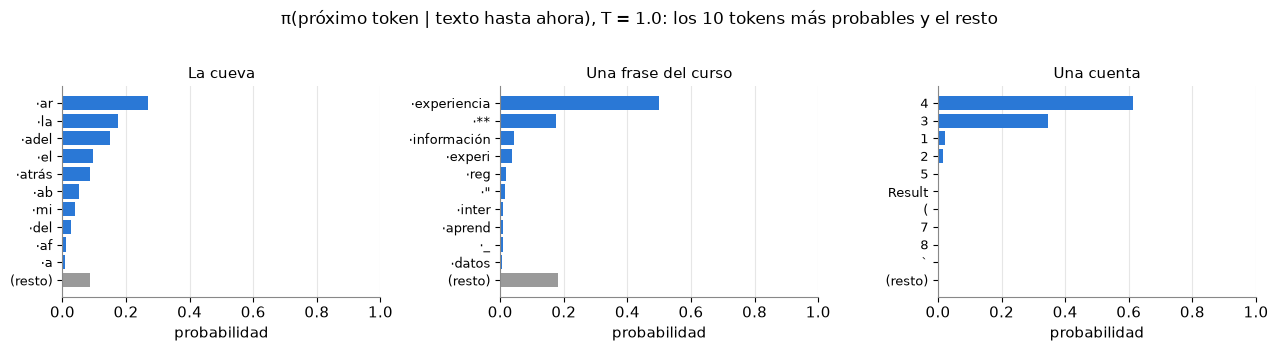

In [6]:
SISTEMA_CUENTAS = "Resolvés cuentas. Escribí la cuenta y el resultado en una sola línea, por ejemplo: 9 + 6 = 15"
ESTADOS = [
    {"nombre": "La cueva", "usuario": "Estás en una cueva a oscuras y acabás de tocar una pared a tu derecha. ¿Qué hacés?",
     "prefijo": "Doy un paso hacia"},
    {"nombre": "Una frase del curso", "usuario": "Completá la frase con una palabra: un agente de aprendizaje por refuerzo aprende de la...",
     "prefijo": "Un agente de aprendizaje por refuerzo aprende de la"},
    {"nombre": "Una cuenta", "sistema": SISTEMA_CUENTAS, "usuario": "¿Cuánto es 17 + 25?", "prefijo": ""},
]
for e in ESTADOS:
    e["texto"] = texto_chat(usuario(e["usuario"], e.get("sistema")), e["prefijo"])
    e["logits"] = logits_proximo(e["texto"])
    p = politica(e["logits"])
    v, i = p.topk(5)
    print(f"{e['nombre']}  (estado = {n_tokens(e['texto'])} tokens, prefijo {e['prefijo']!r})")
    for j, pj in zip(i.tolist(), v.tolist()):
        print(f"    {mostrar_token(tok.decode([j]))!r:<16} {pj:.3f}")
    print(f"    los 5 juntos: {float(v.sum()):.3f}")
dibujar_politica(ESTADOS)

**Qué mirar.** La política no es una sola respuesta: es una distribución. Leé las cifras de arriba: en la cueva y en la frase la masa se reparte entre varias continuaciones razonables (y algunas no tanto); en la cuenta (17 + 25 = 42), casi toda la masa se reparte entre «4» y «3». El «3» es el comienzo de una respuesta equivocada (en la sección 3 vamos a ver salir «32»): muestreando, el modelo a veces empieza mal, y eso es lo que el RL puede corregir.

**Paso 2 — El estado incluye la conversación entera.** El modelo no ve solo la pregunta: ve el texto con la *plantilla de chat* (quién habla, dónde empieza la respuesta). Este es el estado de la cueva tal cual lo recibe:

In [7]:
print(ESTADOS[0]["texto"])

<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
Estás en una cueva a oscuras y acabás de tocar una pared a tu derecha. ¿Qué hacés?<|im_end|>
<|im_start|>assistant
Doy un paso hacia


## 2. La respuesta como episodio

**Paso 1 — Un episodio, token por token.** Cada acción agrega un token al estado, y el estado nuevo es el texto con ese token al final. Jugamos el episodio con la política *greedy* (siempre el token más probable) desde el estado de la cueva. La tabla muestra, en cada paso, el largo del estado, la acción elegida y la probabilidad que le daba la política.

In [8]:
filas = episodio_greedy(ESTADOS[0]["texto"], pasos=12)
print(f"{'paso':>4}  {'estado (tokens)':>15}  {'acción':<16} {'π(acción | estado)':>18}")
for k, (n, t, p) in enumerate(filas, 1):
    print(f"{k:>4}  {n:>15}  {mostrar_token(t)!r:<16} {p:>18.3f}")
print("\nrespuesta greedy:", ESTADOS[0]["prefijo"] + "".join(t for _, t, _ in filas if t != "<fin>"))

paso  estado (tokens)  acción           π(acción | estado)
   1               62  '·ar'                         0.269
   2               63  'riba'                        1.000
   3               64  ','                           0.420
   4               65  '·intent'                     0.074
   5               66  'ando'                        0.976
   6               67  '·encontrar'                  0.174
   7               68  '·una'                        0.256
   8               69  '·salida'                     0.312
   9               70  '·o'                          0.303
  10               71  '·un'                         0.194
  11               72  '·camino'                     0.402
  12               73  '.'                           0.295

respuesta greedy: Doy un paso hacia arriba, intentando encontrar una salida o un camino.


Dos puentes con clases anteriores:

- **Clase 3 (cadena de Markov):** si el estado es *todo* el texto, el proceso es de Markov por construcción: el próximo token depende solo del estado. El precio es que el estado crece en cada paso.
- **Clase 9 (redes recurrentes):** la red recurrente resumía la historia en un vector de tamaño fijo y predecía el próximo carácter. Un modelo como Qwen (un *transformer*) no resume: **relee todo el texto** en cada paso. Cómo lo hace por dentro no entra en este curso.

**Paso 2 — ¿Y la recompensa?** En la cueva, una partida da 0 en cada paso y +1 al entrar a la salida. Una respuesta de texto tiene la misma forma: ningún token suelto «está bien»; recién al terminar alguien (o algo) dice si la respuesta sirvió. Lo vemos lado a lado: el camino más corto en la cueva y la respuesta greedy del modelo a una cuenta, con un verificador que pone 1 si el resultado es correcto (lo armamos en la sección 4).

Cueva: 20 pasos, recompensas distintas de 0 = 1 (la última, +1)
Cuenta: ¿Cuánto es 14 × 12?  respuesta greedy = '14 × 12 = 168'  (12 tokens, contando el fin)
        recompensa al final = 1  (correcta: 168)


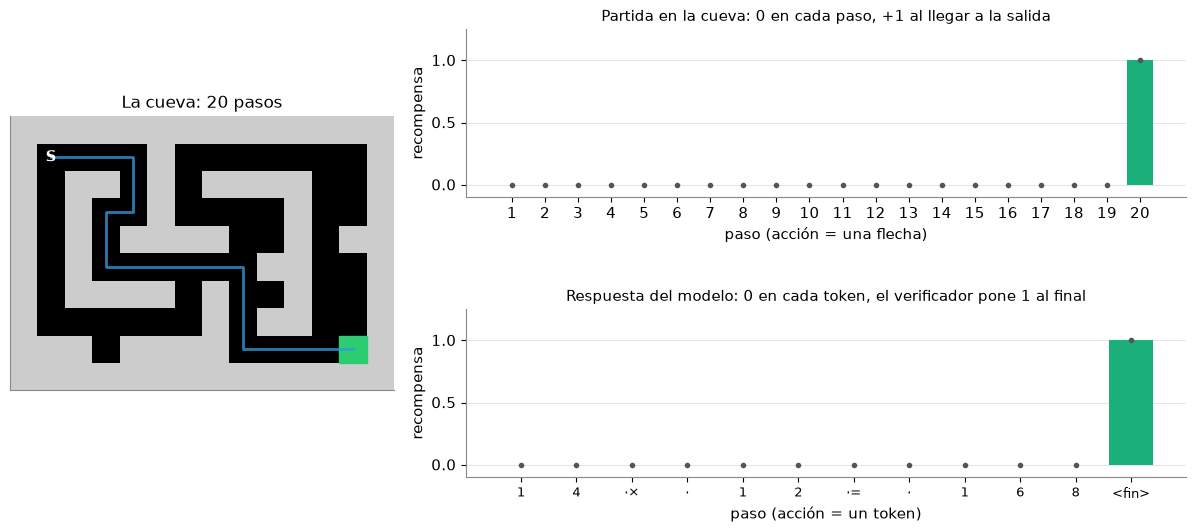

In [9]:
env = CaveEnv()
camino = camino_mas_corto(env)
env.reset()
r_cueva = [env.step(next(a for a in range(4) if env._move(s, a)[0] == s2))[1] for s, s2 in zip(camino, camino[1:])]

CUENTA_EPISODIO = ("¿Cuánto es 14 × 12?", 168)
filas_c = episodio_greedy(texto_chat(usuario(CUENTA_EPISODIO[0], SISTEMA_CUENTAS)), pasos=20)
tokens_c = [t for _, t, _ in filas_c]
respuesta_c = "".join(t for t in tokens_c if t != "<fin>")
r_final = verificador(respuesta_c, CUENTA_EPISODIO[1])
r_texto = [0.0] * (len(tokens_c) - 1) + [r_final]

print(f"Cueva: {len(r_cueva)} pasos, recompensas distintas de 0 = {sum(1 for r in r_cueva if r)} (la última, {r_cueva[-1]:+.0f})")
print(f"Cuenta: {CUENTA_EPISODIO[0]}  respuesta greedy = {respuesta_c!r}  ({len(tokens_c)} tokens, contando el fin)")
print(f"        recompensa al final = {r_final:.0f}  (correcta: {CUENTA_EPISODIO[1]})")
dibujar_dos_episodios(env, camino, r_cueva, tokens_c, r_texto)

Es el mismo molde que en todo el curso:

| | Cueva | Modelo de lenguaje |
|---|---|---|
| estado | la casilla | el texto hasta ahora |
| acción | una de 4 flechas | uno de ~151 mil tokens |
| episodio | una partida | una respuesta (hasta el token de fin) |
| recompensa | +1 al llegar a la salida | un número al terminar la respuesta |

Que la recompensa llegue tarde es el problema de siempre: ¿qué token tuvo el mérito? Policy gradient (clase 11) lo resuelve como en la cueva: si la respuesta entera salió mejor de lo esperado, se refuerzan **todos** sus tokens.

## 3. Temperatura y muestreo

Para usar la política hay que elegir un token. Greedy elige siempre el más probable; **muestrear** elige al azar con las probabilidades de la política. La **temperatura** $T$ divide los *logits* (los puntajes que el modelo da a cada token antes de convertirlos en probabilidades):

$$\pi_T(\text{token} \mid \text{texto}) = \operatorname{softmax}\!\left(\frac{\text{logits}}{T}\right)$$

Con $T$ chica, el más probable se queda con casi todo (explotar); con $T = 1$ es la política del modelo tal cual; con $T$ grande la distribución se aplana (explorar).

**Paso 1 — La misma política a tres temperaturas.** La entropía (en nats) mide qué tan repartida está la masa: 0 si un solo token se lleva todo.

La cueva             T=0.3: P(más probable) = 0.697, entropía = 0.96  |  T=1.0: P(más probable) = 0.269, entropía = 2.46  |  T=1.8: P(más probable) = 0.059, entropía = 7.74
Una frase del curso  T=0.3: P(más probable) = 0.970, entropía = 0.14  |  T=1.0: P(más probable) = 0.498, entropía = 2.66  |  T=1.8: P(más probable) = 0.042, entropía = 9.08
Una cuenta           T=0.3: P(más probable) = 0.872, entropía = 0.38  |  T=1.0: P(más probable) = 0.613, entropía = 0.86  |  T=1.8: P(más probable) = 0.236, entropía = 6.52


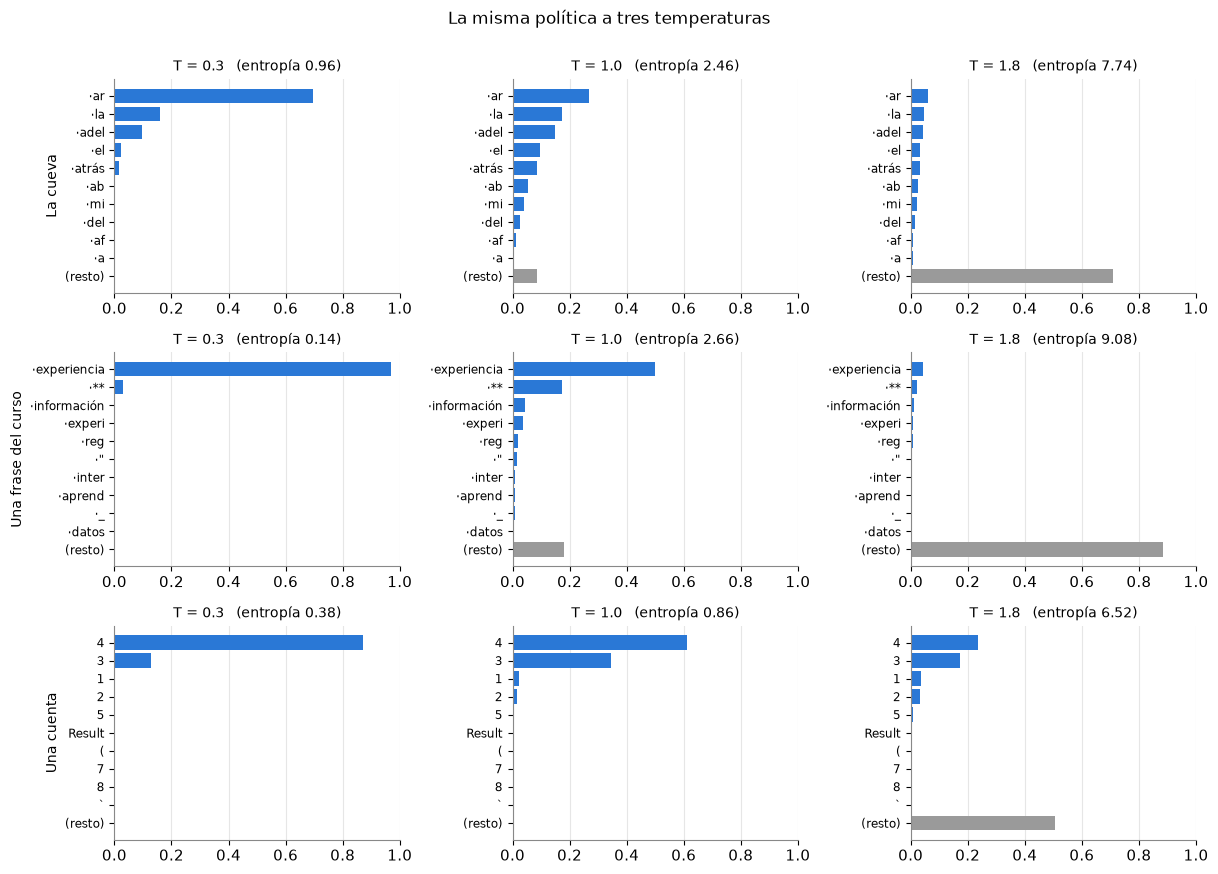

In [10]:
TEMPS_FIG = (0.3, 1.0, 1.8)
for e in ESTADOS:
    linea = []
    for T in TEMPS_FIG:
        p = politica(e["logits"], T)
        linea.append(f"T={T}: P(más probable) = {float(p.max()):.3f}, entropía = {entropia(p):.2f}")
    print(f"{e['nombre']:<20} " + "  |  ".join(linea))
dibujar_temperaturas(ESTADOS, TEMPS_FIG)

**Paso 2 — Entropía contra temperatura.** La curva completa, para los tres estados: a más temperatura, más repartida la política. La entropía máxima posible, con todos los tokens igual de probables, sería $\ln(151\,665) \approx 11{,}9$ nats.

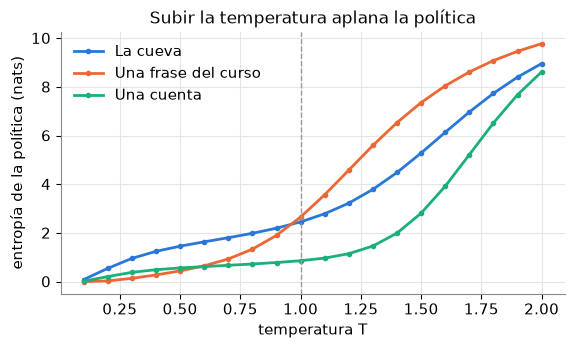

máximo posible con 151665 tokens: 11.93 nats


In [11]:
temps = np.round(np.arange(0.1, 2.001, 0.1), 2)
plt.figure(figsize=(6.5, 3.4))
for c, e in enumerate(ESTADOS):
    H = [entropia(politica(e["logits"], T)) for T in temps]
    e["entropias"] = dict(zip(temps.tolist(), H))
    plt.plot(temps, H, "o-", ms=3, color=COLORES[c], label=e["nombre"])
plt.axvline(1, color=GRIS, ls="--", lw=1)
plt.xlabel("temperatura T"); plt.ylabel("entropía de la política (nats)"); plt.legend(frameon=False)
plt.title("Subir la temperatura aplana la política"); plt.show()
print(f"máximo posible con {len(tok)} tokens: {np.log(len(tok)):.2f} nats")

**Paso 3 — Muestrear 1 o 50 tokens.** Un solo token muestreado no dice mucho: puede salir el más probable o no. Con 50 se ve la política. Muestreamos 50 veces el próximo token desde el estado de la cueva a cuatro temperaturas y contamos cuántos tokens distintos aparecen.

T=0.2:  1 token → '·la'         50 tokens →  2 distintos; los más frecuentes: '·ar'×45, '·la'×5
T=0.7:  1 token → '·la'         50 tokens →  9 distintos; los más frecuentes: '·ar'×18, '·la'×12, '·adel'×7, '·el'×4
T=1.2:  1 token → '·la'         50 tokens → 25 distintos; los más frecuentes: '·ar'×9, '·la'×8, '·el'×4, '·adel'×4
T=1.8:  1 token → '·cri'        50 tokens → 42 distintos; los más frecuentes: '·adel'×5, '·ar'×3, '·ab'×2, '·del'×2


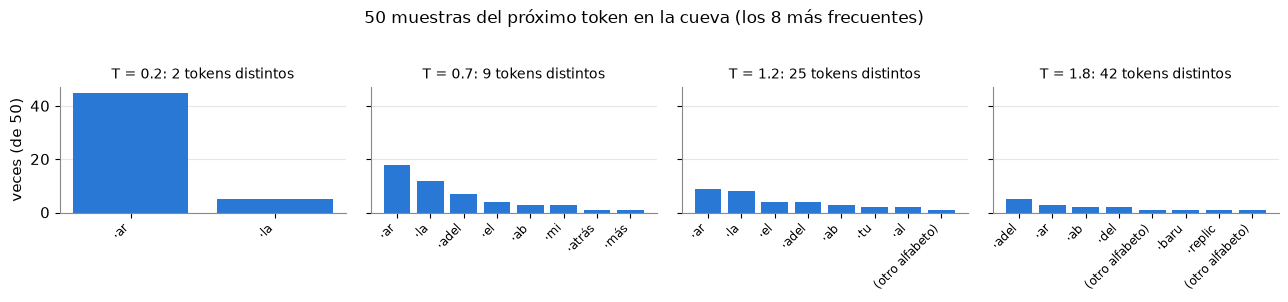

In [12]:
TEMPS = [0.2, 0.7, 1.2, 1.8]
lg_cueva = ESTADOS[0]["logits"]
MUESTRAS_TOKENS = {}
for T in TEMPS:
    uno = muestrear_tokens(lg_cueva, T, n=1, semilla=1)[0]
    cin = muestrear_tokens(lg_cueva, T, n=50, semilla=2)
    cuenta = Counter(cin)
    MUESTRAS_TOKENS[T] = cuenta
    top = ", ".join(f"{mostrar_token(t)!r}×{n}" for t, n in cuenta.most_common(4))
    print(f"T={T}:  1 token → {mostrar_token(uno)!r:<12}  50 tokens → {len(cuenta):>2} distintos; los más frecuentes: {top}")

fig, axs = plt.subplots(1, len(TEMPS), figsize=(13, 2.9), sharey=True)
for ax, T in zip(axs, TEMPS):
    mc = MUESTRAS_TOKENS[T].most_common(8)
    ax.bar(range(len(mc)), [n for _, n in mc], color=COLORES[0])
    ax.set_xticks(range(len(mc))); ax.set_xticklabels([etiqueta(t) for t, _ in mc], rotation=45, ha="right", fontsize=8.5)
    ax.set_title(f"T = {T}: {len(MUESTRAS_TOKENS[T])} tokens distintos", fontsize=10); ax.grid(axis="x", visible=False)
axs[0].set_ylabel("veces (de 50)")
fig.suptitle("50 muestras del próximo token en la cueva (los 8 más frecuentes)", y=1.03)
plt.tight_layout(); plt.show()

**Paso 4 — Respuestas completas.** Ahora muestreamos respuestas enteras (cortas: 12 tokens) desde cada estado, tres por temperatura. Para el RL, esta variedad es la **exploración**: si todas las respuestas son iguales, no hay nada que comparar ni nada nuevo que reforzar. Pero mirá qué pasa con $T$ alta.

In [13]:
for i, e in enumerate(ESTADOS):
    e["muestras"] = {}
    print(f"— {e['nombre']}  (prefijo: {e['prefijo']!r})")
    for T in TEMPS:
        rs = muestrear(e["texto"], n=3, T=T, max_nuevos=12, semilla=10 * i + int(10 * T))
        e["muestras"][T] = rs
        print(f"   T={T}:  " + "  |  ".join(corto(r.replace(chr(10), ' '), 40) for r in rs))

— La cueva  (prefijo: 'Doy un paso hacia')


   T=0.2:  arriba para explorar el entorno más all…  |  arriba para explorar la cueva y descubr…  |  arriba para ver lo que está detrás de m…


   T=0.7:  abajo. Estoy buscando algo que podría a…  |  arriba por la pared a mi derecha. Ya no  |  la derecha. Aun así, no puedo decir con


   T=1.2:  arriba hermosamente y miro por lafila  |  la derecha después de tocar una pared, …  |  abajo hasta encontrarme con la luz que …


   T=1.8:  Liberation Maria.net ang hizo remarcohi…  |  abajo prem тот никогда быть Сергей! ear…  |  procesióninars aproxim横 altInteger...世界…
— Una frase del curso  (prefijo: 'Un agente de aprendizaje por refuerzo aprende de la')


...

   T=1.8:  tarea replacingってきて嘞lutiod.A resolver i…  |  misión complotada intentid metreSecret_…  |  experiencia clipboardley (...词条Operatio…
— Una cuenta  (prefijo: '')


   T=0.2:  42  |  42  |  42


   T=0.7:  42  |  42  |  32


   T=1.2:  42 Factors 30 Be The First Other decepc…  |  32  |  42


   T=1.8:  Overlayntaxacosmocardsexolestasm感じ期末央.R…  |  脘 quarters hun-and Another lieu goodste…  |  std ü뇌 unsafe values nie rs黍 Litecoinみん…


**Qué mirar.** Con $T = 0{,}2$ las tres respuestas son casi iguales: explotar. Con $T = 0{,}7$ aparece variedad con sentido. Con $T = 1{,}8$ la política aplanada le da chance a miles de tokens raros y el texto se rompe (otros idiomas, pedazos de código). Explorar no es gratis: demasiada temperatura produce basura, como un $\varepsilon$ demasiado grande en la cueva (clase 6). En la cuenta, fijate si alguna muestra con temperatura media ya da un resultado equivocado: el modelo no «sabe» la respuesta, la elige con cierta probabilidad.

✍️ **Ejercicio.** Cambiá el `prefijo` de la cueva en la sección 1 (por ejemplo `"Doy un paso hacia la"`) y volvé a correr las secciones 1 y 3. ¿Qué tokens aparecen? ¿Son palabras enteras o pedazos? ¿A qué temperatura empieza a romperse el texto?

## 4. Un verificador para cuentas

¿Quién pone el número al final de la respuesta? En la clase 12 la recompensa la **aprendía** un modelo a partir de comparaciones de personas (RLHF, Ouyang et al., 2022): sirve para cosas difíciles de definir, como «una respuesta útil y amable», pero el modelo de recompensa se puede equivocar y se puede engañar. Cuando la pregunta tiene una respuesta que se puede **chequear** (una cuenta, un código con sus tests), la recompensa la puede dar un programa: una **recompensa verificable**. Es la que usan DeepSeekMath (Shao et al., 2024) y DeepSeek-R1 (DeepSeek-AI, 2025).

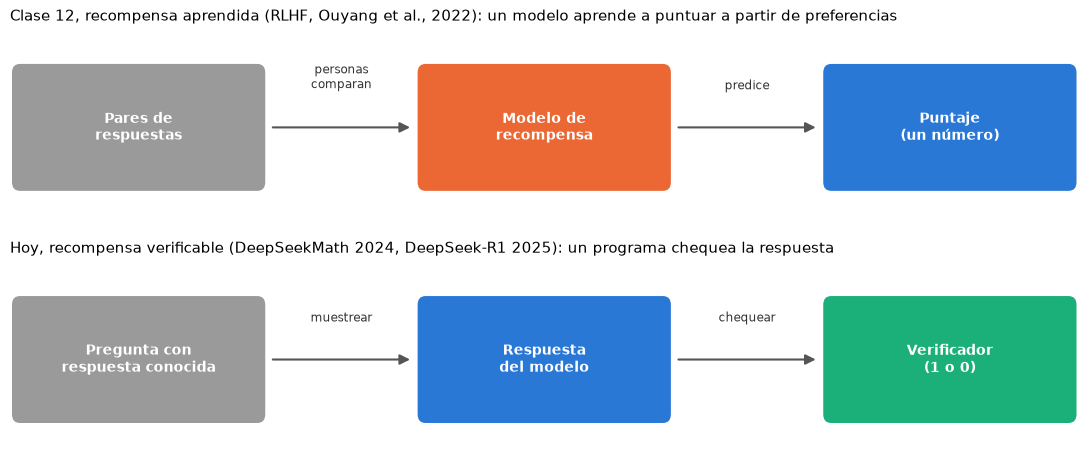

In [14]:
dibujar_aprendida_vs_verificable()

**Paso 1 — El verificador.** El nuestro es estricto y simple: toma el **último número** de la respuesta y da 1 si coincide con el resultado correcto, 0 si no. Lo probamos con respuestas escritas a mano para la cuenta 17 + 25 = 42, incluidas algunas en las que se equivoca el verificador y no quien responde.

In [15]:
PRUEBAS = ["42", "17 + 25 = 42", "17 + 25 = 32", "La respuesta es 42.", "Es 42, o tal vez 41",
           "cuarenta y dos", "42 + 0 = 42", "No sé"]
print(f"{'respuesta':<24} {'último número':>14} {'recompensa':>11}")
for x in PRUEBAS:
    u = ultimo_numero(x)
    print(f"{x!r:<24} {('—' if u is None else f'{u:g}'):>14} {verificador(x, 42):>11.0f}")

respuesta                 último número  recompensa
'42'                                 42           1
'17 + 25 = 42'                       42           1
'17 + 25 = 32'                       32           0
'La respuesta es 42.'                42           1
'Es 42, o tal vez 41'                41           0
'cuarenta y dos'                      —           0
'42 + 0 = 42'                        42           1
'No sé'                               —           0


El verificador no lee palabras: «cuarenta y dos» vale 0 aunque sea correcto. Y si una respuesta dudosa termina en el número justo, cobra. Un verificador es un programa con reglas, y la política aprende a cumplir **esas** reglas; qué pasa cuando se las puede engañar es tema de la clase 14. Lo que no se puede chequear con un programa (si una explicación es clara, si un consejo es bueno) sigue pidiendo comparaciones y una recompensa aprendida.

**Paso 2 — Las cuentas y la respuesta greedy.** Armamos doce cuentas, de fáciles a no tan fáciles, y le pedimos al modelo la respuesta greedy de cada una. El verificador dice cuántas acierta.

In [16]:
CUENTAS = [("17 + 25", 42), ("8 × 7", 56), ("63 − 28", 35), ("3 × 4 + 5", 17), ("125 + 76", 201), ("14 × 12", 168),
           ("23 × 17", 391), ("256 − 189", 67), ("2 + 3 × 4", 14), ("19 × 21", 399), ("1000 − 357", 643), ("7 × 8 − 9", 47)]
GREEDY = []
for cuenta, correcta in CUENTAS:
    texto = texto_chat(usuario(f"¿Cuánto es {cuenta}?", SISTEMA_CUENTAS))
    x = muestrear(texto, T=0, max_nuevos=16)[0]
    r = verificador(x, correcta)
    GREEDY.append(r)
    print(f"{cuenta:<12} = {correcta:<5} greedy: {corto(x.replace(chr(10), ' '), 40)!r:<44} recompensa {r:.0f}")
print(f"\nAciertos greedy: {int(sum(GREEDY))} de {len(CUENTAS)} ({100 * np.mean(GREEDY):.0f} %)")

17 + 25      = 42    greedy: '42'                                         recompensa 1


8 × 7        = 56    greedy: '56'                                         recompensa 1


63 − 28      = 35    greedy: '35'                                         recompensa 1


3 × 4 + 5    = 17    greedy: '23'                                         recompensa 0


125 + 76     = 201   greedy: '125 + 76 = 201'                             recompensa 1


...

256 − 189    = 67    greedy: '47'                                         recompensa 0


2 + 3 × 4    = 14    greedy: '14'                                         recompensa 1


19 × 21      = 399   greedy: '399'                                        recompensa 1


1000 − 357   = 643   greedy: '643'                                        recompensa 1


7 × 8 − 9    = 47    greedy: '43'                                         recompensa 0

Aciertos greedy: 9 de 12 (75 %)


## 5. Ventajas de GRPO en un grupo

GRPO (*Group Relative Policy Optimization*, Shao et al., 2024) hace, para cada pregunta: (1) **muestrear un grupo** de $G$ respuestas con la política actual; (2) **puntuarlas** con la recompensa (acá, el verificador); (3) calcular la **ventaja** de cada una comparándola con el resto del grupo:

$$A_i = \frac{r_i - \text{promedio}(r_1, \dots, r_G)}{\text{desvío}(r_1, \dots, r_G)}$$

y (4) dar un paso que haga más probables las respuestas con ventaja positiva y menos probables las de ventaja negativa. Hoy hacemos (1), (2) y (3) con números reales del modelo; el paso (4), entrenar, queda afuera.

**Paso 1 — Muestrear y puntuar.** Para cada una de las doce cuentas, un grupo de $G = 8$ respuestas a $T = 1$ (la política tal cual, sin recortes).

In [17]:
G = 8
GRUPOS = []
for k, (cuenta, correcta) in enumerate(CUENTAS):
    texto = texto_chat(usuario(f"¿Cuánto es {cuenta}?", SISTEMA_CUENTAS))
    rs = muestrear(texto, n=G, T=1.0, max_nuevos=16, semilla=k)
    r = np.array([verificador(x, correcta) for x in rs])
    GRUPOS.append({"cuenta": cuenta, "correcta": correcta, "texto": texto, "respuestas": rs,
                   "recompensas": r, "ventajas": ventajas_grpo(r)})
    print(f"{cuenta:<12} = {correcta:<5} recompensas {''.join(str(int(x)) for x in r)}   promedio {r.mean():.3f}")
todas = np.concatenate([g["recompensas"] for g in GRUPOS])
print(f"\nAciertos muestreando a T = 1: {int(todas.sum())} de {len(todas)} respuestas ({100 * todas.mean():.1f} %)")

17 + 25      = 42    recompensas 11101110   promedio 0.750


8 × 7        = 56    recompensas 11111111   promedio 1.000


63 − 28      = 35    recompensas 11111111   promedio 1.000


3 × 4 + 5    = 17    recompensas 10000000   promedio 0.125


125 + 76     = 201   recompensas 11111111   promedio 1.000


...

256 − 189    = 67    recompensas 01100100   promedio 0.375


2 + 3 × 4    = 14    recompensas 10001010   promedio 0.375


19 × 21      = 399   recompensas 11111111   promedio 1.000


1000 − 357   = 643   recompensas 11111111   promedio 1.000


7 × 8 − 9    = 47    recompensas 00000000   promedio 0.000

Aciertos muestreando a T = 1: 65 de 96 respuestas (67.7 %)


**Paso 2 — Una cuenta en detalle.** Tomamos el primer grupo **mixto** (con aciertos y errores) y hacemos la cuenta de las ventajas a mano: promedio, desvío y, para cada respuesta, $(r_i - \text{promedio}) / \text{desvío}$.

In [18]:
DETALLE = next(x for x in GRUPOS if 0 < x["recompensas"].mean() < 1)
r = DETALLE["recompensas"]
media, desvio = r.mean(), r.std()
print(f"¿Cuánto es {DETALLE['cuenta']}?   correcta: {DETALLE['correcta']}")
print(f"promedio del grupo = {media:.3f}   desvío = {desvio:.3f}\n")
print(f"{'i':>2}  {'respuesta':<34} {'r':>3} {'r − prom.':>10} {'ventaja A':>10}")
for i, (x, ri, ai) in enumerate(zip(DETALLE["respuestas"], r, DETALLE["ventajas"]), 1):
    print(f"{i:>2}  {corto(x.replace(chr(10), ' '), 34):<34} {ri:>3.0f} {ri - media:>+10.3f} {ai:>+10.3f}")
print(f"\nsuma de las ventajas = {DETALLE['ventajas'].sum():+.3f}  (siempre ≈ 0: unas suben y otras bajan)")

¿Cuánto es 17 + 25?   correcta: 42
promedio del grupo = 0.750   desvío = 0.433

 i  respuesta                            r  r − prom.  ventaja A
 1  42                                   1     +0.250     +0.577
 2  42                                   1     +0.250     +0.577
 3  42                                   1     +0.250     +0.577
 4  32                                   0     -0.750     -1.732
 5  42                                   1     +0.250     +0.577
 6  42                                   1     +0.250     +0.577
 7  42                                   1     +0.250     +0.577
 8  32                                   0     -0.750     -1.732

suma de las ventajas = +0.000  (siempre ≈ 0: unas suben y otras bajan)


**Paso 3 — Los doce grupos.** Cada panel es una cuenta; cada barra, una respuesta, pintada según el verificador, con su ventaja como altura.

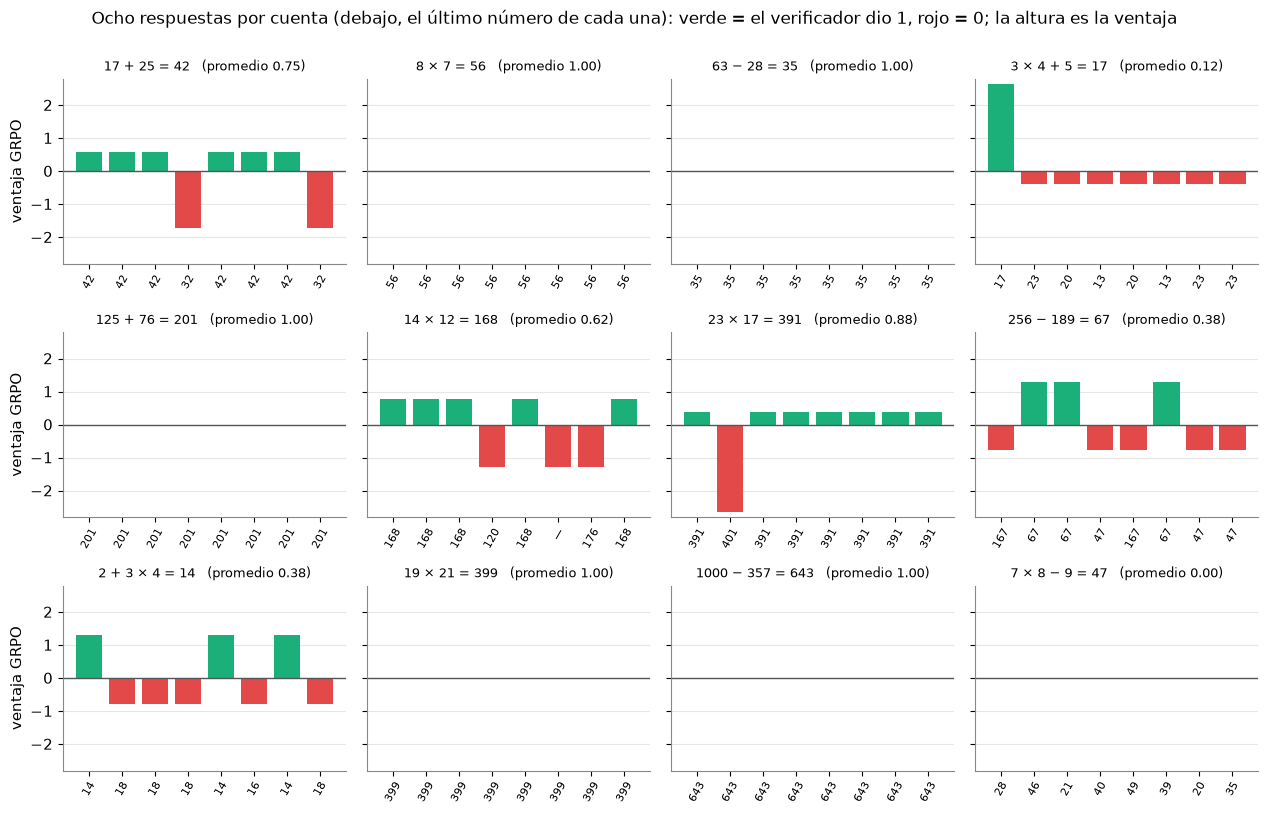

grupos mixtos (dan señal): 6 de 12
todas bien (ventaja 0): 5 → ['8 × 7', '63 − 28', '125 + 76', '19 × 21', '1000 − 357']
todas mal  (ventaja 0): 1 → ['7 × 8 − 9']


In [19]:
dibujar_grupos(GRUPOS)
mixtos = [g for g in GRUPOS if 0 < g["recompensas"].mean() < 1]
todos_bien = [g["cuenta"] for g in GRUPOS if g["recompensas"].mean() == 1]
todos_mal = [g["cuenta"] for g in GRUPOS if g["recompensas"].mean() == 0]
print(f"grupos mixtos (dan señal): {len(mixtos)} de {len(GRUPOS)}")
print(f"todas bien (ventaja 0): {len(todos_bien)} → {todos_bien}")
print(f"todas mal  (ventaja 0): {len(todos_mal)} → {todos_mal}")

**Paso 4 — Los errores del modelo.** Antes de seguir, leé las respuestas que el verificador rechazó. Algunas son resultados equivocados; otras son respuestas cortadas o con otro formato.

In [20]:
for g in GRUPOS:
    malas = Counter(x.replace(chr(10), " ") for x, ri in zip(g["respuestas"], g["recompensas"]) if not ri)
    if malas:
        print(f"{g['cuenta']} = {g['correcta']}:  " + "  |  ".join(f"{corto(x, 32)!r}×{n}" for x, n in malas.most_common(4)))

17 + 25 = 42:  '32'×2
3 × 4 + 5 = 17:  '23'×3  |  '20'×2  |  '13'×2
14 × 12 = 168:  '120'×1  |  "They're equal."×1  |  '176'×1
23 × 17 = 391:  '401'×1
256 − 189 = 67:  '47'×3  |  '167'×2
2 + 3 × 4 = 14:  '18'×4  |  '16'×1
7 × 8 − 9 = 47:  '28'×1  |  '46'×1  |  '21'×1  |  '40'×1


**Qué mirar.** Los grupos **mixtos** dan señal: ventaja positiva a las correctas, negativa a las incorrectas, y una respuesta correcta en un grupo donde casi todas fallan recibe una ventaja grande (es una sorpresa buena). Los grupos donde **todas** valen lo mismo tienen ventaja cero: GRPO no aprende nada de esa cuenta en ese paso. Si el modelo nunca acierta una cuenta, no hay de dónde aprender: es la recompensa escasa de la clase 7, ahora con texto. Por eso conviene entrenar con preguntas que el modelo a veces acierta y a veces no.

✍️ **Ejercicio.** Cambiá `G = 8` por `G = 4` o `G = 16`, o la temperatura del Paso 1 a `0.5`, y volvé a correr la sección. ¿Cuántos grupos mixtos quedan? ¿Por qué con $T$ más baja hay menos señal?

## 6. El grupo como línea de base

En la clase 11, el policy gradient reforzaba cada acción con «cuánto mejor salió de lo esperado»: el retorno menos una **línea de base** $b(s)$. En actor-crítico, la línea de base la daba un **crítico**, una segunda red que aprende $V(s)$, y PPO la usaba con un recorte para no alejarse demasiado de la política anterior. Para un modelo de lenguaje, el crítico tendría que estimar, para cada texto, qué recompensa se espera: otra red tan grande como la política, que hay que entrenar a la par.

GRPO se ahorra el crítico: para estimar qué se espera de una pregunta, **pregunta varias veces** y promedia. El promedio del grupo hace de $V(\text{pregunta})$.

**Paso 1 — ¿Qué tan buena es esa línea de base?** Para cada cuenta muestreamos cuatro grupos más de 8 (40 respuestas por cuenta en total) y comparamos el promedio de cada grupo con el promedio de las 40.

cuenta       promedios de los 5 grupos de 8      promedio de 40
17 + 25      0.750  0.750  0.750  0.500  0.375            0.625
8 × 7        1.000  1.000  1.000  1.000  1.000            1.000
63 − 28      1.000  1.000  1.000  1.000  0.750            0.950
3 × 4 + 5    0.125  0.125  0.000  0.000  0.125            0.075
125 + 76     1.000  0.750  0.750  0.875  0.750            0.825
14 × 12      0.625  0.750  0.250  0.500  0.375            0.500
23 × 17      0.875  0.875  1.000  0.875  0.875            0.900
256 − 189    0.375  0.125  0.250  0.250  0.125            0.225
2 + 3 × 4    0.375  0.375  0.375  0.750  0.750            0.525
19 × 21      1.000  1.000  1.000  0.875  1.000            0.975
1000 − 357   1.000  1.000  0.875  1.000  1.000            0.975
7 × 8 − 9    0.000  0.000  0.000  0.000  0.125            0.025

mayor distancia entre el promedio más alto y el más bajo de una misma cuenta: 0.500 (14 × 12)
Aciertos en las 480 respuestas muestreadas a T = 1: 63.3 %


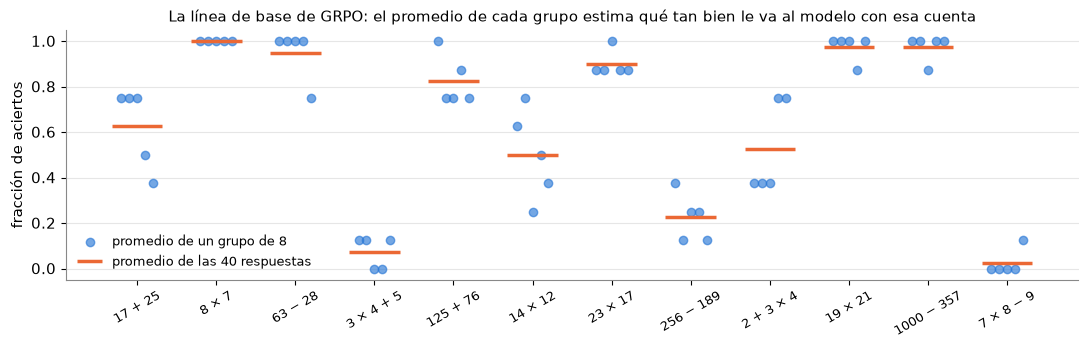

In [21]:
EXTRA = []
for k, g in enumerate(GRUPOS):
    EXTRA.append([np.array([verificador(x, g["correcta"]) for x in muestrear(g["texto"], n=G, T=1.0, max_nuevos=16, semilla=100 * (k + 1) + m)])
                  for m in range(4)])
print(f"{'cuenta':<12} {'promedios de los 5 grupos de 8':<34} {'promedio de 40':>15}")
for g, ex in zip(GRUPOS, EXTRA):
    medias = [g["recompensas"].mean()] + [x.mean() for x in ex]
    tot = np.concatenate([g["recompensas"]] + ex).mean()
    print(f"{g['cuenta']:<12} {'  '.join(f'{m:.3f}' for m in medias):<34} {tot:>15.3f}")
rangos = [(max([g["recompensas"].mean()] + [x.mean() for x in ex]) - min([g["recompensas"].mean()] + [x.mean() for x in ex]), g["cuenta"])
          for g, ex in zip(GRUPOS, EXTRA)]
print(f"\nmayor distancia entre el promedio más alto y el más bajo de una misma cuenta: {max(rangos)[0]:.3f} ({max(rangos)[1]})")
todas40 = np.concatenate([np.concatenate([g["recompensas"]] + ex) for g, ex in zip(GRUPOS, EXTRA)])
print(f"Aciertos en las {len(todas40)} respuestas muestreadas a T = 1: {100 * todas40.mean():.1f} %")
dibujar_lineas_de_base(GRUPOS, EXTRA)

**Qué mirar.** Cada punto azul es la línea de base que GRPO usaría con un grupo de 8; la raya naranja, una estimación mejor con 40 respuestas. Los puntos se reparten alrededor de la raya, y en algunas cuentas bastante lejos (la cifra impresa arriba dice cuánto en la peor): la línea de base del grupo es **ruidosa**, como un $V(s)$ estimado con pocas partidas. A cambio, no hay que entrenar nada para obtenerla, y es de la pregunta exacta que se está respondiendo. Con más respuestas por grupo, menos ruido (y más cómputo): el artículo de DeepSeekMath muestrea 64 por pregunta.

**Paso 2 — El tamaño del crítico que nos ahorramos.** Un crítico para este modelo sería, en la práctica, otra red del mismo tamaño que la política.

In [22]:
n_param = sum(p.numel() for p in modelo.parameters())
print(f"política (Qwen2.5-0.5B): {n_param / 1e6:.0f} millones de parámetros")
print(f"con un crítico del mismo tamaño: {2 * n_param / 1e6:.0f} millones para entrenar y tener en memoria")
print(f"GRPO: {n_param / 1e6:.0f} millones, más {G} respuestas por pregunta para promediar")

política (Qwen2.5-0.5B): 494 millones de parámetros
con un crítico del mismo tamaño: 988 millones para entrenar y tener en memoria
GRPO: 494 millones, más 8 respuestas por pregunta para promediar


**Paso 3 — El recorte de PPO sigue estando.** Con la ventaja $A_i$ ya calculada, GRPO actualiza la política como PPO (clase 11): compara la probabilidad de la respuesta con la política nueva y con la vieja, $\rho = \pi_{\text{nueva}} / \pi_{\text{vieja}}$, y recorta ese cociente a la franja $[1 - \varepsilon, 1 + \varepsilon]$:

$$\text{objetivo}_i = \min\big(\rho_i A_i,\ \operatorname{recorte}(\rho_i, 1-\varepsilon, 1+\varepsilon)\, A_i\big)$$

Además suma una penalización para no alejarse demasiado del modelo de partida (la divergencia KL, como en RLHF). Dibujamos el objetivo para dos ventajas reales del grupo de la sección 5: la de una respuesta correcta y la de una incorrecta.

¿Cuánto es 17 + 25?  ventaja de una correcta = +0.577, de una incorrecta = -1.732


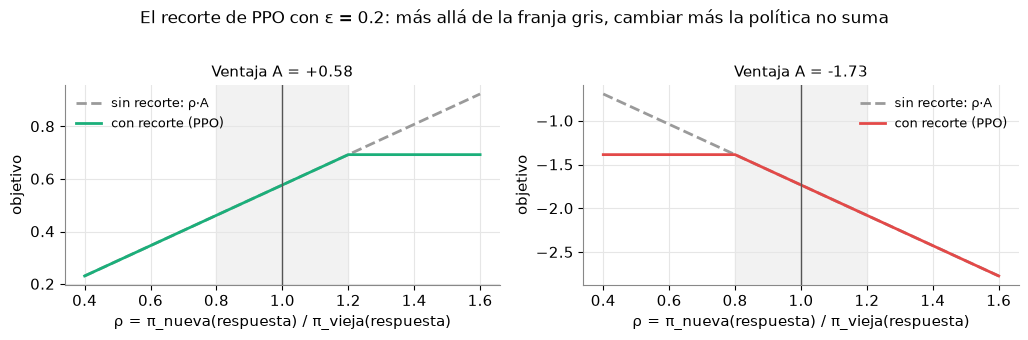

In [23]:
A_buena = float(DETALLE["ventajas"][DETALLE["recompensas"] == 1][0])
A_mala = float(DETALLE["ventajas"][DETALLE["recompensas"] == 0][0])
print(f"¿Cuánto es {DETALLE['cuenta']}?  ventaja de una correcta = {A_buena:+.3f}, de una incorrecta = {A_mala:+.3f}")
dibujar_recorte([A_buena, A_mala], eps=0.2)

**Qué mirar.** Con ventaja positiva, subir la probabilidad de la respuesta mejora el objetivo solo hasta $\rho = 1{,}2$; con ventaja negativa, bajarla sirve solo hasta $\rho = 0{,}8$. Es la misma idea de la clase 11: reforzar lo que salió mejor que lo esperado, sin alejarse mucho de la política anterior en un solo paso. Lo único que cambió es **de dónde sale lo esperado**: del grupo, no de un crítico.

DeepSeek-R1 (DeepSeek-AI, 2025) usa GRPO con recompensas verificables de exactitud y de formato; su versión R1-Zero se entrenó solo con RL sobre un modelo base, sin ajuste supervisado previo. Nosotros nos quedamos en las ventajas: el paso de entrenamiento, repetido miles de veces sobre todo el modelo, necesita GPU y horas.

## Preguntas para pensar

1. En GRPO, un grupo donde todas las respuestas son correctas tiene ventaja cero. ¿Es un problema o una virtud? ¿Qué cuentas de la sección 5 conviene usar para entrenar este modelo?
2. Nuestro verificador le da 0 a «cuarenta y dos». Si entrenaras con él, ¿qué aprendería el modelo además de sumar? ¿Está mal que lo aprenda?
3. Pensá en un asistente que escribe resúmenes de clases. ¿Qué partes de un buen resumen se podrían verificar con un programa y cuáles necesitarían comparaciones de personas, como en la clase 12?

## Próxima clase

El modelo escribe, pero no hace nada fuera del texto. En la clase 14, **agentes de lenguaje**: el mismo modelo dentro de un bucle que piensa, pide herramientas (buscar, calcular) y observa el resultado (ReAct), con un programa alrededor que decide qué se ejecuta, y los riesgos de optimizar una recompensa que se puede engañar.

In [24]:
print(f"Tiempo total del notebook: {(time.time() - T0) / 60:.1f} min · modelo: {MODELO} · dispositivo: {DEVICE}")

Tiempo total del notebook: 7.1 min · modelo: Qwen/Qwen2.5-0.5B-Instruct · dispositivo: cpu
